# ConvNeXt-Tiny + SNN + CBAM + Vision Transformer — Binary Tumor / No Tumor

This notebook preserves the supplied ConvNeXt + SNN + CBAM + ViT model architecture and adapts its classifier and evaluation to **two classes**.

The data recipe follows `FFT_Model_best.ipynb`:
- Mendeley images are pooled from both `Train` and `Test` folders, then sampled: up to 3,300 glioma, 2,800 meningioma, 2,000 pituitary, and all no-tumor images.
- 44-class MRI images: 171 Astrocitoma T2, 233 Meningioma T2, 57 Ependimoma T2, and 271 Normal T2.
- All tumor subtypes map to label `1` (`Tumor`); all normal/no-tumor images map to label `0` (`No Tumor`).
- The independent `brain_mri_detection` yes/no dataset remains the external test set, as in the FFT notebook.
- The combined training pool is split 80% train / 20% validation with stratification (random_state=42).

No Kaggle API token or `kaggle.json` is used. Public Kaggle datasets are downloaded with `kagglehub`.


## 1. Install dependencies

In [1]:
!pip install -q timm torchmetrics thop grad-cam kaggle kagglehub torchinfo

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## 2. Imports and reproducibility

In [2]:
import os
import json
import random
import shutil
import zipfile
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import timm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, matthews_corrcoef, confusion_matrix,
    classification_report
)
from thop import profile
from torchinfo import summary

sns.set_style("darkgrid")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
print("Device:", device)
print("Mixed precision:", USE_AMP)
print("timm version:", timm.__version__)
from timm.models.vision_transformer import VisionTransformer


Device: cuda
Mixed precision: True
timm version: 1.0.30


## 3. Dataset access (no Kaggle API credentials)

This notebook does not request or create `kaggle.json`. It uses the Mendeley ZIP already uploaded to Colab and `kagglehub` for the two public Kaggle datasets.

In [3]:
# Locate and extract the Mendeley ZIP already uploaded to Google Colab.
# This cell does NOT call files.upload() and does NOT require kaggle.json.

WORK_DIR = Path("/content/brain_tumor_fft_sources")
MENDELEY_EXTRACTED = WORK_DIR / "mendeley_dataset"
WORK_DIR.mkdir(parents=True, exist_ok=True)
MENDELEY_EXTRACTED.mkdir(parents=True, exist_ok=True)

def find_mendeley_root(search_dir):
    search_dir = Path(search_dir)
    candidates = [search_dir] + [p for p in search_dir.rglob("*") if p.is_dir()]
    for folder in candidates:
        children = {p.name.lower(): p for p in folder.iterdir() if p.is_dir()}
        if "train" in children and "test" in children:
            return folder
    return None

# Reuse any extracted copy already present in /content.
MENDELEY_ROOT = find_mendeley_root(Path("/content"))

if MENDELEY_ROOT is None:
    zip_candidates = [
        p for p in Path("/content").glob("*.zip")
        if p.is_file() and WORK_DIR not in p.parents
    ]
    matching = [
        p for p in zip_candidates
        if "brain tumor" in p.name.lower() or "glioma" in p.name.lower()
    ]
    if not matching:
        raise FileNotFoundError(
            "Mendeley ZIP not found in /content. Upload the dataset ZIP "
            "through Colab's Files panel first; do not upload kaggle.json."
        )

    SOURCE_ZIP = matching[0]
    if not zipfile.is_zipfile(SOURCE_ZIP):
        raise ValueError(f"Uploaded file is not a valid ZIP archive: {SOURCE_ZIP}")

    print("Using already-uploaded archive:", SOURCE_ZIP)
    with zipfile.ZipFile(SOURCE_ZIP, "r") as zf:
        zf.extractall(MENDELEY_EXTRACTED)

    # The outer archive may contain Epic and CSCR hospital Dataset.zip.
    processed = set()
    while True:
        nested_zips = [
            p for p in MENDELEY_EXTRACTED.rglob("*.zip")
            if str(p) not in processed
        ]
        if not nested_zips:
            break
        for nested_zip in nested_zips:
            processed.add(str(nested_zip))
            if not zipfile.is_zipfile(nested_zip):
                print("Skipping invalid nested archive:", nested_zip)
                continue
            target = nested_zip.parent / nested_zip.stem
            target.mkdir(parents=True, exist_ok=True)
            print("Extracting nested archive:", nested_zip.name)
            with zipfile.ZipFile(nested_zip, "r") as zf:
                zf.extractall(target)

    MENDELEY_ROOT = find_mendeley_root(MENDELEY_EXTRACTED)

if MENDELEY_ROOT is None:
    raise FileNotFoundError(
        "Could not find the Mendeley root containing Train and Test folders."
    )

print("Mendeley root:", MENDELEY_ROOT)
print("Train folder:", MENDELEY_ROOT / "Train")
print("Test folder:", MENDELEY_ROOT / "Test")

Using already-uploaded archive: /content/Brain Tumor MRI Dataset (Glioma, Meningioma, Pitui.zip
Extracting nested archive: Epic and CSCR hospital Dataset.zip
Mendeley root: /content/brain_tumor_fft_sources/mendeley_dataset/Brain Tumor MRI Dataset (Glioma, Meningioma, Pitui/Epic and CSCR hospital Dataset/Epic and CSCR hospital Dataset
Train folder: /content/brain_tumor_fft_sources/mendeley_dataset/Brain Tumor MRI Dataset (Glioma, Meningioma, Pitui/Epic and CSCR hospital Dataset/Epic and CSCR hospital Dataset/Train
Test folder: /content/brain_tumor_fft_sources/mendeley_dataset/Brain Tumor MRI Dataset (Glioma, Meningioma, Pitui/Epic and CSCR hospital Dataset/Epic and CSCR hospital Dataset/Test


## 4. Download the public 44-class training source and independent binary test source

Both are public Kaggle datasets accessed through `kagglehub`; no Kaggle API key is embedded or requested.

In [4]:
import kagglehub

# FFT_Model_best sources
DATA44_SLUG = "fernando2rad/brain-tumor-mri-images-44c"
EXTERNAL_TEST_SLUG = "navoneel/brain-mri-images-for-brain-tumor-detection"

print("Downloading / locating public 44-class dataset with kagglehub...")
DATA44_DIR = Path(kagglehub.dataset_download(DATA44_SLUG))
print("44-class dataset:", DATA44_DIR)

print("\nDownloading / locating independent yes/no test dataset...")
EXTERNAL_TEST_DIR = Path(kagglehub.dataset_download(EXTERNAL_TEST_SLUG))
print("External test dataset:", EXTERNAL_TEST_DIR)

100%|██████████| 188M/188M [00:05<00:00, 38.3MB/s]

Extracting files...


44-class dataset: /root/.cache/kagglehub/datasets/fernando2rad/brain-tumor-mri-images-44c/versions/1



100%|██████████| 15.1M/15.1M [00:01<00:00, 14.7MB/s]

Extracting files...


External test dataset: /root/.cache/kagglehub/datasets/navoneel/brain-mri-images-for-brain-tumor-detection/versions/1


## 5. Build the binary dataset using the FFT notebook's exact sampling recipe

Tumor subtype images (glioma, meningioma, pituitary, astrocitoma, ependimoma) receive label `1`. No-tumor / normal images receive label `0`. The separate `yes` / `no` dataset is reserved for final testing.

In [5]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

# Binary labels match FFT_Model_best.ipynb and the requested report format.
CLASS_NAMES = ["No Tumor", "Tumor"]
label_map = {"No Tumor": 0, "Tumor": 1}
idx_to_class = {0: "No Tumor", 1: "Tumor"}
num_classes = 2
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

def collect_images(folder, label, source_name):
    folder = Path(folder)
    records = []
    if not folder.exists():
        return records
    for image_path in folder.rglob("*"):
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTS:
            records.append({
                "image_path": str(image_path.resolve()),
                "label": int(label),
                "class_name": CLASS_NAMES[int(label)],
                "source": source_name
            })
    return records

def sample_images(records, n=None):
    records = list(records)
    if n is None:
        return records
    return random.sample(records, min(int(n), len(records)))

def first_existing_child(parent, aliases):
    parent = Path(parent)
    if not parent.exists():
        return None
    by_normalized = {
        re.sub(r"[^a-z0-9]", "", p.name.lower()): p
        for p in parent.iterdir() if p.is_dir()
    }
    for alias in aliases:
        key = re.sub(r"[^a-z0-9]", "", alias.lower())
        if key in by_normalized:
            return by_normalized[key]
    return None

# ------------------------------------------------------------
# DATASET 1: MENDELEY
# Pool BOTH Train and Test folders exactly as in FFT notebook.
# ------------------------------------------------------------
print("=" * 65)
print("Loading Mendeley Dataset")
print("=" * 65)

mendeley_specs = {
    "glioma": (["glioma"], 1, 3300),
    "meningioma": (["meningioma"], 1, 2800),
    "pituitary": (["pituitary"], 1, 2000),
    "notumor": (["notumor", "no_tumor", "normal", "no tumor"], 0, None)
}
mendeley_records = {}

for key, (aliases, label, limit) in mendeley_specs.items():
    records = []
    for split_name in ["Train", "Test"]:
        split_dir = MENDELEY_ROOT / split_name
        class_dir = first_existing_child(split_dir, aliases)
        if class_dir is not None:
            records.extend(collect_images(class_dir, label, "Mendeley"))
    # De-duplicate paths in case the extracted archive has repeated references.
    records = list({r["image_path"]: r for r in records}.values())
    mendeley_records[key] = sample_images(records, limit)

print(f"Mendeley glioma      : {len(mendeley_records['glioma'])}")
print(f"Mendeley meningioma  : {len(mendeley_records['meningioma'])}")
print(f"Mendeley pituitary   : {len(mendeley_records['pituitary'])}")
print(f"Mendeley no_tumor    : {len(mendeley_records['notumor'])}")

# ------------------------------------------------------------
# DATASET 2: 44-CLASS DATASET
# Exact FFT sampling; Ependimoma is INCLUDED as Tumor.
# ------------------------------------------------------------
print("\n" + "=" * 65)
print("Loading 44-Class Dataset")
print("=" * 65)

def find_named_t2_folders(root, aliases):
    matches = []
    for folder in Path(root).rglob("*"):
        if not folder.is_dir():
            continue
        normalized = re.sub(r"[^a-z0-9]", "", folder.name.lower())
        if "t2" not in normalized:
            continue
        if any(alias in normalized for alias in aliases):
            matches.append(folder)
    # Keep the deepest matching folder paths only, preventing parent/child double counts.
    matches = sorted(set(matches), key=lambda p: len(p.parts))
    # If both a matching parent and a matching child exist, keep only the
    # deepest folder so each image is collected once.
    selected = [
        folder for folder in matches
        if not any(
            folder in other.parents
            for other in matches
            if other != folder
        )
    ]
    return selected

def collect_from_matching_folders(root, aliases, label, source_name):
    records = []
    folders = find_named_t2_folders(root, aliases)
    for folder in folders:
        records.extend(collect_images(folder, label, source_name))
    return list({r["image_path"]: r for r in records}.values())

astro = sample_images(
    collect_from_matching_folders(DATA44_DIR, ["astrocitoma", "astrocytoma"], 1, "44-class"),
    171
)
men_t2 = sample_images(
    collect_from_matching_folders(DATA44_DIR, ["meningioma"], 1, "44-class"),
    233
)
epend = sample_images(
    collect_from_matching_folders(DATA44_DIR, ["ependimoma", "ependymoma"], 1, "44-class"),
    57
)
normal = sample_images(
    collect_from_matching_folders(DATA44_DIR, ["normal"], 0, "44-class"),
    271
)

print(f"Astrocitoma T2      : {len(astro)}")
print(f"Meningioma T2       : {len(men_t2)}")
print(f"Ependimoma T2       : {len(epend)}")
print(f"Normal T2           : {len(normal)}")

# Fail rather than silently training without the 44-class source.
expected_44 = {"Astrocitoma T2": 171, "Meningioma T2": 233,
               "Ependimoma T2": 57, "Normal T2": 271}
actual_44 = {"Astrocitoma T2": len(astro), "Meningioma T2": len(men_t2),
             "Ependimoma T2": len(epend), "Normal T2": len(normal)}
missing_44 = {k: (v, actual_44[k]) for k, v in expected_44.items()
              if actual_44[k] == 0}
if missing_44:
    raise RuntimeError(
        "One or more expected 44-class folders produced zero images: "
        f"{missing_44}. Inspect DATA44_DIR and its folder names before training."
    )

# ------------------------------------------------------------
# COMBINED TRAINING POOL: BINARY LABELS
# ------------------------------------------------------------
training_records = []
for key in ["glioma", "meningioma", "pituitary", "notumor"]:
    training_records.extend(mendeley_records[key])
training_records.extend(astro)
training_records.extend(men_t2)
training_records.extend(epend)
training_records.extend(normal)

# Deduplicate by absolute image path, then shuffle deterministically.
training_records = list({
    r["image_path"]: r for r in training_records
}.values())
random.Random(SEED).shuffle(training_records)
training_df = pd.DataFrame(training_records)

# ------------------------------------------------------------
# INDEPENDENT TEST DATASET: brain_mri_detection/yes and /no
# Keep this separate, as in FFT_Model_best.ipynb.
# ------------------------------------------------------------
def find_yes_no_root(root):
    root = Path(root)
    candidates = [root] + [p for p in root.rglob("*") if p.is_dir()]
    for folder in candidates:
        child_names = {
            re.sub(r"[^a-z0-9]", "", p.name.lower()): p
            for p in folder.iterdir() if p.is_dir()
        }
        if "yes" in child_names and "no" in child_names:
            return folder, child_names["yes"], child_names["no"]
    return None, None, None

test_root, yes_dir, no_dir = find_yes_no_root(EXTERNAL_TEST_DIR)
if test_root is None:
    raise FileNotFoundError(
        "Could not locate yes/ and no/ folders in external test dataset: "
        f"{EXTERNAL_TEST_DIR}"
    )

test_records = (
    collect_images(yes_dir, 1, "External brain_mri_detection") +
    collect_images(no_dir, 0, "External brain_mri_detection")
)
test_records = list({r["image_path"]: r for r in test_records}.values())
external_test_df = pd.DataFrame(test_records)

if training_df.empty or external_test_df.empty:
    raise RuntimeError("Training or external test dataframe is empty.")

# ------------------------------------------------------------
# DATASET SUMMARY IN TUMOR / NO TUMOR FORMAT
# ------------------------------------------------------------
print("\n" + "=" * 65)
print("FFT-STYLE DATASET SUMMARY")
print("=" * 65)

print("\nMendeley source counts:")
for key, title in [
    ("glioma", "Glioma"), ("meningioma", "Meningioma"),
    ("pituitary", "Pituitary"), ("notumor", "No Tumor")
]:
    print(f"{title:20s}: {len(mendeley_records[key]):,}")

print("\n44-class source counts:")
print(f"{'Astrocitoma T2':20s}: {len(astro):,}")
print(f"{'Meningioma T2':20s}: {len(men_t2):,}")
print(f"{'Ependimoma T2':20s}: {len(epend):,}")
print(f"{'Normal T2':20s}: {len(normal):,}")

print("\nCombined training pool:")
print(training_df["class_name"].value_counts().reindex(CLASS_NAMES, fill_value=0))
print("Total training-pool images:", len(training_df))

print("\nIndependent external test set:")
print(external_test_df["class_name"].value_counts().reindex(CLASS_NAMES, fill_value=0))
print("Total external test images:", len(external_test_df))

assert set(training_df["label"].unique()) == {0, 1}
assert set(external_test_df["label"].unique()) == {0, 1}
print("\nBinary label mapping:", label_map)

Loading Mendeley Dataset
Mendeley glioma      : 3300
Mendeley meningioma  : 2729
Mendeley pituitary   : 2000
Mendeley no_tumor    : 2432

Loading 44-Class Dataset
Astrocitoma T2      : 171
Meningioma T2       : 233
Ependimoma T2       : 57
Normal T2           : 271

FFT-STYLE DATASET SUMMARY

Mendeley source counts:
Glioma              : 3,300
Meningioma          : 2,729
Pituitary           : 2,000
No Tumor            : 2,432

44-class source counts:
Astrocitoma T2      : 171
Meningioma T2       : 233
Ependimoma T2       : 57
Normal T2           : 271

Combined training pool:
class_name
No Tumor    2703
Tumor       8490
Name: count, dtype: int64
Total training-pool images: 11193

Independent external test set:
class_name
No Tumor     98
Tumor       155
Name: count, dtype: int64
Total external test images: 253

Binary label mapping: {'No Tumor': 0, 'Tumor': 1}


## 6. FFT-style train / validation split and independent test set

The FFT notebook uses an 80/20 stratified split of the combined training pool for train and validation, while keeping `brain_mri_detection/yes` and `/no` as a separate, unchanged external test set. No random images from the external test set are moved into training or validation.

In [6]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    training_df,
    test_size=0.20,
    random_state=SEED,
    stratify=training_df["label"]
)

# Test remains the independent yes/no dataset from FFT_Model_best.
test_df = external_test_df.copy()

def show_binary_distribution(name, frame):
    counts = frame["class_name"].value_counts().reindex(CLASS_NAMES, fill_value=0)
    print(f"\n{name}: {len(frame):,} images")
    print(counts.to_string())
    print("Label counts:")
    print(frame["label"].value_counts().reindex([0, 1], fill_value=0)
          .rename(index={0: "No Tumor (0)", 1: "Tumor (1)"}).to_string())

print("=" * 65)
print("TRAIN / VALIDATION / EXTERNAL TEST SUMMARY")
print("=" * 65)
print(f"Train      : {len(train_df):,} ({len(train_df)/len(training_df):.1%} of training pool)")
print(f"Validation : {len(val_df):,} ({len(val_df)/len(training_df):.1%} of training pool)")
print(f"Test       : {len(test_df):,} (independent external test set)")

show_binary_distribution("TRAIN", train_df)
show_binary_distribution("VALIDATION", val_df)
show_binary_distribution("TEST", test_df)

for split_name, split_df in [
    ("train", train_df), ("validation", val_df), ("test", test_df)
]:
    if set(split_df["label"].unique()) != {0, 1}:
        raise ValueError(f"{split_name} split must contain both binary labels.")

TRAIN / VALIDATION / EXTERNAL TEST SUMMARY
Train      : 8,954 (80.0% of training pool)
Validation : 2,239 (20.0% of training pool)
Test       : 253 (independent external test set)

TRAIN: 8,954 images
class_name
No Tumor    2162
Tumor       6792
Label counts:
label
No Tumor (0)    2162
Tumor (1)       6792

VALIDATION: 2,239 images
class_name
No Tumor     541
Tumor       1698
Label counts:
label
No Tumor (0)     541
Tumor (1)       1698

TEST: 253 images
class_name
No Tumor     98
Tumor       155
Label counts:
label
No Tumor (0)     98
Tumor (1)       155


## 7. Dataset, transforms, and dataloaders

In [7]:
class BrainTumorDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row["image_path"]).convert("RGB")
        if self.transform is not None:
            image = self.transform(image)
        return image, torch.tensor(int(row["label"]), dtype=torch.long)

train_transform = transforms.Compose([
    transforms.Resize((448, 448)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.ColorJitter(brightness=0.10, contrast=0.10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((448, 448)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

BATCH_SIZE = 8  # Memory-conscious for ConvNeXt + CBAM + ViT
NUM_WORKERS = 2
pin_memory = device.type == "cuda"

train_loader = DataLoader(BrainTumorDataset(train_df, train_transform),
                          batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=pin_memory)
val_loader = DataLoader(BrainTumorDataset(val_df, val_test_transform),
                        batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=pin_memory)
test_loader = DataLoader(BrainTumorDataset(test_df, val_test_transform),
                         batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=pin_memory)

print("Batches:", len(train_loader), len(val_loader), len(test_loader))

Batches: 1120 280 32


In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm

from timm.models.vision_transformer import VisionTransformer


# ============================================================
# 1. SURROGATE SPIKE FUNCTION
# ============================================================

class SurrogateSpike(torch.autograd.Function):

    @staticmethod
    def forward(ctx, x):
        ctx.save_for_backward(x)
        return (x > 0).float()

    @staticmethod
    def backward(ctx, grad_output):

        (x,) = ctx.saved_tensors

        slope = 5.0

        grad = 1.0 / (
            1.0 + slope * torch.abs(x)
        ) ** 2

        return grad_output * grad


# ============================================================
# 2. LIF NEURON
# ============================================================

class LIFNeuron(nn.Module):

    def __init__(
        self,
        threshold=1.0,
        beta=0.97,
        num_steps=4
    ):

        super().__init__()

        self.threshold = threshold
        self.beta = beta
        self.num_steps = num_steps

    def forward(self, current):

        membrane = torch.zeros_like(current)

        spike_sequence = []

        for t in range(self.num_steps):

            membrane = (
                self.beta * membrane + current
            )

            spike = SurrogateSpike.apply(
                membrane - self.threshold
            )

            membrane = (
                membrane -
                spike.detach() * self.threshold
            )

            spike_sequence.append(spike)

        return torch.stack(
            spike_sequence,
            dim=0
        ).mean(dim=0)


# ============================================================
# 3. SINGLE SNN BLOCK
# ============================================================

class SNNBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        kernel_size=3,
        padding=1,
        beta=0.97,
        threshold=1.0,
        num_steps=4
    ):

        super().__init__()

        self.conv = nn.Conv2d(
            in_channels=in_channels,
            out_channels=out_channels,
            kernel_size=kernel_size,
            stride=1,
            padding=padding,
            bias=False
        )

        self.bn = nn.BatchNorm2d(
            out_channels
        )

        self.lif = LIFNeuron(
            threshold=threshold,
            beta=beta,
            num_steps=num_steps
        )

        self.skip = (
            nn.Identity()
            if in_channels == out_channels
            else nn.Sequential(
                nn.Conv2d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )
        )

    def forward(self, x):

        identity = self.skip(x)

        current = self.conv(x)

        current = self.bn(current)

        spike_output = self.lif(current)

        return identity + spike_output


# ============================================================
# 4. CBAM MODULE
# ============================================================

class ChannelAttention(nn.Module):

    def __init__(
        self,
        channels,
        reduction=16
    ):

        super().__init__()

        hidden_channels = max(
            channels // reduction,
            1
        )

        self.shared_mlp = nn.Sequential(

            nn.Conv2d(
                channels,
                hidden_channels,
                kernel_size=1,
                bias=False
            ),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                hidden_channels,
                channels,
                kernel_size=1,
                bias=False
            )
        )

    def forward(self, x):

        avg_pool = F.adaptive_avg_pool2d(
            x, 1
        )

        max_pool = F.adaptive_max_pool2d(
            x, 1
        )

        avg_out = self.shared_mlp(
            avg_pool
        )

        max_out = self.shared_mlp(
            max_pool
        )

        attention = torch.sigmoid(
            avg_out + max_out
        )

        return x * attention


class SpatialAttention(nn.Module):

    def __init__(self, kernel_size=7):

        super().__init__()

        self.conv = nn.Conv2d(
            2,
            1,
            kernel_size=kernel_size,
            padding=kernel_size // 2,
            bias=False
        )

    def forward(self, x):

        avg_pool = torch.mean(
            x,
            dim=1,
            keepdim=True
        )

        max_pool = torch.max(
            x,
            dim=1,
            keepdim=True
        )[0]

        combined = torch.cat(
            [avg_pool, max_pool],
            dim=1
        )

        attention = torch.sigmoid(
            self.conv(combined)
        )

        return x * attention


class CBAM(nn.Module):

    def __init__(
        self,
        channels,
        reduction=16,
        spatial_kernel=7
    ):

        super().__init__()

        self.channel_attention = ChannelAttention(
            channels,
            reduction
        )

        self.spatial_attention = SpatialAttention(
            spatial_kernel
        )

    def forward(self, x):

        x = self.channel_attention(x)

        x = self.spatial_attention(x)

        return x


# ============================================================
# 5. CBAM DILATED CONVOLUTION BRANCH
# ============================================================

class CBAMBranch(nn.Module):

    def __init__(self, in_channels=192):

        super().__init__()

        # CBAM attention on ConvNeXt feature map

        self.cbam = CBAM(
            channels=in_channels,
            reduction=16,
            spatial_kernel=7
        )

        # Max pooling: 56 x 56 -> 28 x 28

        self.max_pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        # Dilated convolution:
        # 192 channels -> 96 channels
        # dilation rate = 2

        self.dilated_conv = nn.Sequential(

            nn.Conv2d(
                in_channels=in_channels,
                out_channels=96,
                kernel_size=3,
                stride=1,
                padding=2,
                dilation=2,
                bias=False
            ),

            nn.BatchNorm2d(96),

            nn.ReLU(inplace=True)
        )

        # Global Average Pooling

        self.gap = nn.AdaptiveAvgPool2d(
            (1, 1)
        )

    def forward(self, x):

        # B, 192, 56, 56

        x = self.cbam(x)

        # B, 192, 56, 56

        x = self.max_pool(x)

        # B, 192, 28, 28

        x = self.dilated_conv(x)

        # B, 96, 28, 28

        x = self.gap(x)

        # B, 96, 1, 1

        x = torch.flatten(
            x,
            start_dim=1
        )

        # B, 96

        return x


# ============================================================
# 6. MAIN SNN + ViT BRANCH
# ============================================================

class SNNViTBranch(nn.Module):

    def __init__(self):

        super().__init__()

        # Only ONE SNN block

        self.snn_block = SNNBlock(
            in_channels=192,
            out_channels=128,
            kernel_size=3,
            padding=1,
            beta=0.97,
            threshold=1.0,
            num_steps=4
        )

        # Max pooling: 56 x 56 -> 28 x 28

        self.max_pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        # 1 x 1 convolution: 128 -> 96

        self.conv1x1 = nn.Sequential(

            nn.Conv2d(
                in_channels=128,
                out_channels=96,
                kernel_size=1,
                stride=1,
                padding=0,
                bias=False
            ),

            nn.BatchNorm2d(96),

            nn.ReLU(inplace=True)
        )

        # 3 x 3 convolution: 96 -> 64

        self.conv3x3 = nn.Sequential(

            nn.Conv2d(
                in_channels=96,
                out_channels=64,
                kernel_size=3,
                stride=1,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(64),

            nn.ReLU(inplace=True)
        )

        # Vision Transformer
        #
        # Input feature map: 64 x 28 x 28
        # Patch size: 7 x 7
        # Number of patches: 4 x 4 = 16

        self.vit_encoder = VisionTransformer(

            img_size=28,

            patch_size=7,

            in_chans=64,

            num_classes=0,

            global_pool="avg",

            embed_dim=64,

            depth=2,

            num_heads=4,

            mlp_ratio=1,

            qkv_bias=True,

            norm_layer=nn.LayerNorm,

            act_layer=nn.ReLU
        )

        self.vit_encoder.head = nn.Identity()

    def forward(self, x):

        # Input: B, 192, 56, 56

        x = self.snn_block(x)

        # B, 128, 56, 56

        x = self.max_pool(x)

        # B, 128, 28, 28

        x = self.conv1x1(x)

        # B, 96, 28, 28

        x = self.conv3x3(x)

        # B, 64, 28, 28

        x = self.vit_encoder(x)

        # B, 64

        return x


# ============================================================
# 7. COMPLETE CONVNEXT + SNN + CBAM + ViT MODEL
# ============================================================

class ConvNeXtSNNViTCBAM(nn.Module):

    def __init__(
        self,
        num_classes,
        pretrained=True
    ):

        super().__init__()

        # ----------------------------------------------------
        # ConvNeXt-Tiny Backbone
        # ----------------------------------------------------

        base = timm.create_model(

            "convnext_tiny",

            pretrained=pretrained,

            num_classes=0
        )

        self.stem = base.stem

        stage1 = base.stages[0]

        stage2 = base.stages[1]

        # Retain only first block of stage 2

        stage2.blocks = nn.Sequential(
            *list(stage2.blocks.children())[:1]
        )

        self.stages = nn.Sequential(
            stage1,
            stage2
        )

        del base

        self.feature_channels = 192

        # ----------------------------------------------------
        # Main SNN + ViT Branch
        # ----------------------------------------------------

        self.main_branch = SNNViTBranch()

        # ----------------------------------------------------
        # Parallel CBAM Branch
        # ----------------------------------------------------

        self.cbam_branch = CBAMBranch(
            in_channels=192
        )

        # ----------------------------------------------------
        # Feature Concatenation
        # ----------------------------------------------------

        self.fusion_dim = 64 + 96

        # ----------------------------------------------------
        # Final Classifier
        # ----------------------------------------------------

        self.classifier = nn.Linear(
            self.fusion_dim,
            num_classes
        )

    # --------------------------------------------------------
    # ConvNeXt Feature Extraction
    # --------------------------------------------------------

    def forward_features(self, x):

        x = self.stem(x)

        x = self.stages(x)

        return x

    # --------------------------------------------------------
    # Complete Feature Extraction
    # --------------------------------------------------------

    def forward_head_features(self, x):

        # Shared ConvNeXt features

        backbone_features = self.forward_features(x)

        # B, 192, 56, 56

        # Main branch: SNN + ViT

        vit_features = self.main_branch(
            backbone_features
        )

        # B, 64

        # Parallel branch: CBAM + Dilated Conv + GAP

        cbam_features = self.cbam_branch(
            backbone_features
        )

        # B, 96

        # Feature concatenation

        fused_features = torch.cat(

            [
                vit_features,
                cbam_features
            ],

            dim=1
        )

        # B, 160

        return fused_features

    # --------------------------------------------------------
    # Final Forward Pass
    # --------------------------------------------------------

    def forward(self, x):

        fused_features = self.forward_head_features(x)

        logits = self.classifier(fused_features)

        return logits


# ============================================================
# 8. MODEL INITIALIZATION
# ============================================================

model = ConvNeXtSNNViTCBAM(

    num_classes=num_classes,

    pretrained=True

).to(device)


# ============================================================
# 9. ARCHITECTURE VERIFICATION
# ============================================================

model.eval()

with torch.no_grad():

    dummy = torch.randn(

        1,
        3,
        448,
        448,

        device=device
    )

    # ConvNeXt output

    backbone_map = model.forward_features(dummy)

    # Main branch

    snn_map = model.main_branch.snn_block(
        backbone_map
    )

    pooled_snn = model.main_branch.max_pool(
        snn_map
    )

    conv1x1_map = model.main_branch.conv1x1(
        pooled_snn
    )

    conv3x3_map = model.main_branch.conv3x3(
        conv1x1_map
    )

    vit_features = model.main_branch.vit_encoder(
        conv3x3_map
    )

    # CBAM branch

    cbam_map = model.cbam_branch.cbam(
        backbone_map
    )

    cbam_pooled = model.cbam_branch.max_pool(
        cbam_map
    )

    dilated_map = model.cbam_branch.dilated_conv(
        cbam_pooled
    )

    cbam_gap = model.cbam_branch.gap(
        dilated_map
    )

    cbam_features = torch.flatten(
        cbam_gap,
        start_dim=1
    )

    # Concatenation

    fused_features = torch.cat(

        [
            vit_features,
            cbam_features
        ],

        dim=1
    )

    # Final output

    logits = model(dummy)

    probabilities = torch.softmax(
        logits,
        dim=1
    )


# ============================================================
# 10. PRINT ALL DIMENSIONS
# ============================================================

retained_block_counts = [

    len(stage.blocks)

    for stage in model.stages
]

print("\n========== ARCHITECTURE VERIFICATION ==========\n")

print(
    "Retained ConvNeXt blocks:",
    retained_block_counts
)

print(
    "ConvNeXt output:",
    tuple(backbone_map.shape)
)

print(
    "After single SNN block:",
    tuple(snn_map.shape)
)

print(
    "After main branch max pooling:",
    tuple(pooled_snn.shape)
)

print(
    "After 1x1 convolution:",
    tuple(conv1x1_map.shape)
)

print(
    "After 3x3 convolution:",
    tuple(conv3x3_map.shape)
)

print(
    "ViT output:",
    tuple(vit_features.shape)
)

print("\n---------- CBAM BRANCH ----------\n")

print(
    "After CBAM:",
    tuple(cbam_map.shape)
)

print(
    "After CBAM max pooling:",
    tuple(cbam_pooled.shape)
)

print(
    "After dilated convolution:",
    tuple(dilated_map.shape)
)

print(
    "After GAP:",
    tuple(cbam_features.shape)
)

print("\n---------- FEATURE FUSION ----------\n")

print(
    "Concatenated features:",
    tuple(fused_features.shape)
)

print(
    "Classifier output:",
    tuple(logits.shape)
)

print(
    "Softmax probabilities:",
    tuple(probabilities.shape)
)


# ============================================================
# 11. DIMENSION ASSERTIONS
# ============================================================

assert retained_block_counts == [3, 1]

assert tuple(backbone_map.shape[1:]) == (
    192, 56, 56
)

assert tuple(snn_map.shape[1:]) == (
    128, 56, 56
)

assert tuple(pooled_snn.shape[1:]) == (
    128, 28, 28
)

assert tuple(conv1x1_map.shape[1:]) == (
    96, 28, 28
)

assert tuple(conv3x3_map.shape[1:]) == (
    64, 28, 28
)

assert tuple(vit_features.shape) == (
    1, 64
)

assert tuple(cbam_map.shape[1:]) == (
    192, 56, 56
)

assert tuple(cbam_pooled.shape[1:]) == (
    192, 28, 28
)

assert tuple(dilated_map.shape[1:]) == (
    96, 28, 28
)

assert tuple(cbam_features.shape) == (
    1, 96
)

assert tuple(fused_features.shape) == (
    1, 160
)

assert tuple(logits.shape) == (
    1, num_classes
)

assert tuple(probabilities.shape) == (
    1, num_classes
)

print("\nAll architecture dimensions verified successfully!")

model.train()

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            


========== ARCHITECTURE VERIFICATION ==========

Retained ConvNeXt blocks: [3, 1]
ConvNeXt output: (1, 192, 56, 56)
After single SNN block: (1, 128, 56, 56)
After main branch max pooling: (1, 128, 28, 28)
After 1x1 convolution: (1, 96, 28, 28)
After 3x3 convolution: (1, 64, 28, 28)
ViT output: (1, 64)

---------- CBAM BRANCH ----------

After CBAM: (1, 192, 56, 56)
After CBAM max pooling: (1, 192, 28, 28)
After dilated convolution: (1, 96, 28, 28)
After GAP: (1, 96)

---------- FEATURE FUSION ----------

Concatenated features: (1, 160)
Classifier output: (1, 2)
Softmax probabilities: (1, 2)

All architecture dimensions verified successfully!


ConvNeXtSNNViTCBAM(
  (stem): Sequential(
    (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
    (1): LayerNorm2d((96,), eps=1e-06, elementwise_affine=True)
  )
  (stages): Sequential(
    (0): ConvNeXtStage(
      (downsample): Identity()
      (blocks): Sequential(
        (0): ConvNeXtBlock(
          (conv_dw): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (norm): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (mlp): Mlp(
            (fc1): Linear(in_features=96, out_features=384, bias=True)
            (act): GELU()
            (drop1): Dropout(p=0.0, inplace=False)
            (norm): Identity()
            (fc2): Linear(in_features=384, out_features=96, bias=True)
            (drop2): Dropout(p=0.0, inplace=False)
          )
          (shortcut): Identity()
          (drop_path): Identity()
        )
        (1): ConvNeXtBlock(
          (conv_dw): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), g

## 9. Model summary and complexity

The model summary includes the four retained ConvNeXt blocks, CBAM, and classification head.

In [9]:
summary(
    model,
    input_size=(1, 3, 448, 448),
    col_names=["input_size", "output_size", "num_params", "kernel_size"],
    depth=4
)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {trainable_params:,}")
print(f"Total parameters: {total_params:,}")

model.eval()
dummy_input = torch.randn(1, 3, 448, 448, device=device)
flops, thop_params = profile(model, inputs=(dummy_input,), verbose=False)
print(f"THOP FLOPs: {flops:,.0f} ({flops / 1e9:.4f} GFLOPs)")
print(f"THOP parameters: {thop_params:,.0f} ({thop_params / 1e6:.4f} M)")
model.train()

Trainable parameters: 1,360,708
Total parameters: 1,360,708
THOP FLOPs: 5,157,130,528 (5.1571 GFLOPs)
THOP parameters: 1,357,732 (1.3577 M)


ConvNeXtSNNViTCBAM(
  (stem): Sequential(
    (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
    (1): LayerNorm2d((96,), eps=1e-06, elementwise_affine=True)
  )
  (stages): Sequential(
    (0): ConvNeXtStage(
      (downsample): Identity()
      (blocks): Sequential(
        (0): ConvNeXtBlock(
          (conv_dw): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (norm): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (mlp): Mlp(
            (fc1): Linear(in_features=96, out_features=384, bias=True)
            (act): GELU()
            (drop1): Dropout(p=0.0, inplace=False)
            (norm): Identity()
            (fc2): Linear(in_features=384, out_features=96, bias=True)
            (drop2): Dropout(p=0.0, inplace=False)
          )
          (shortcut): Identity()
          (drop_path): Identity()
        )
        (1): ConvNeXtBlock(
          (conv_dw): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), g

## 10. Loss, optimizer, and learning-rate schedule

In [10]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=3e-4, weight_decay=1e-4, betas=(0.9, 0.999)
)

TOTAL_EPOCHS = 20
WARMUP_EPOCHS = 5
warmup_scheduler = torch.optim.lr_scheduler.LinearLR(
    optimizer, start_factor=0.1, end_factor=1.0, total_iters=WARMUP_EPOCHS
)
cosine_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=TOTAL_EPOCHS - WARMUP_EPOCHS, eta_min=1e-6
)

scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
BEST_MODEL_PATH = "best_convnext_cbam_vit.pth"
print("Checkpoint:", BEST_MODEL_PATH)

Checkpoint: best_convnext_cbam_vit.pth


## 11. Metric helpers

In [11]:
def specificity_sensitivity(y_true, y_pred, n_classes):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(n_classes)))
    specificity, sensitivity = [], []
    for i in range(n_classes):
        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = cm.sum() - (tp + fn + fp)
        specificity.append(tn / (tn + fp + 1e-8))
        sensitivity.append(tp / (tp + fn + 1e-8))
    return float(np.mean(specificity)), float(np.mean(sensitivity))


def calculate_metrics(y_true, y_pred, y_prob, n_classes):
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "mcc": matthews_corrcoef(y_true, y_pred),
    }
    try:
        if n_classes == 2:
            metrics["auc"] = roc_auc_score(y_true, y_prob[:, 1])
        else:
            metrics["auc"] = roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro")
    except ValueError:
        metrics["auc"] = float("nan")
    metrics["specificity"], metrics["sensitivity"] = specificity_sensitivity(
        y_true, y_pred, n_classes
    )
    return metrics

In [12]:
!pip install torchinfo thop torchview graphviz -q

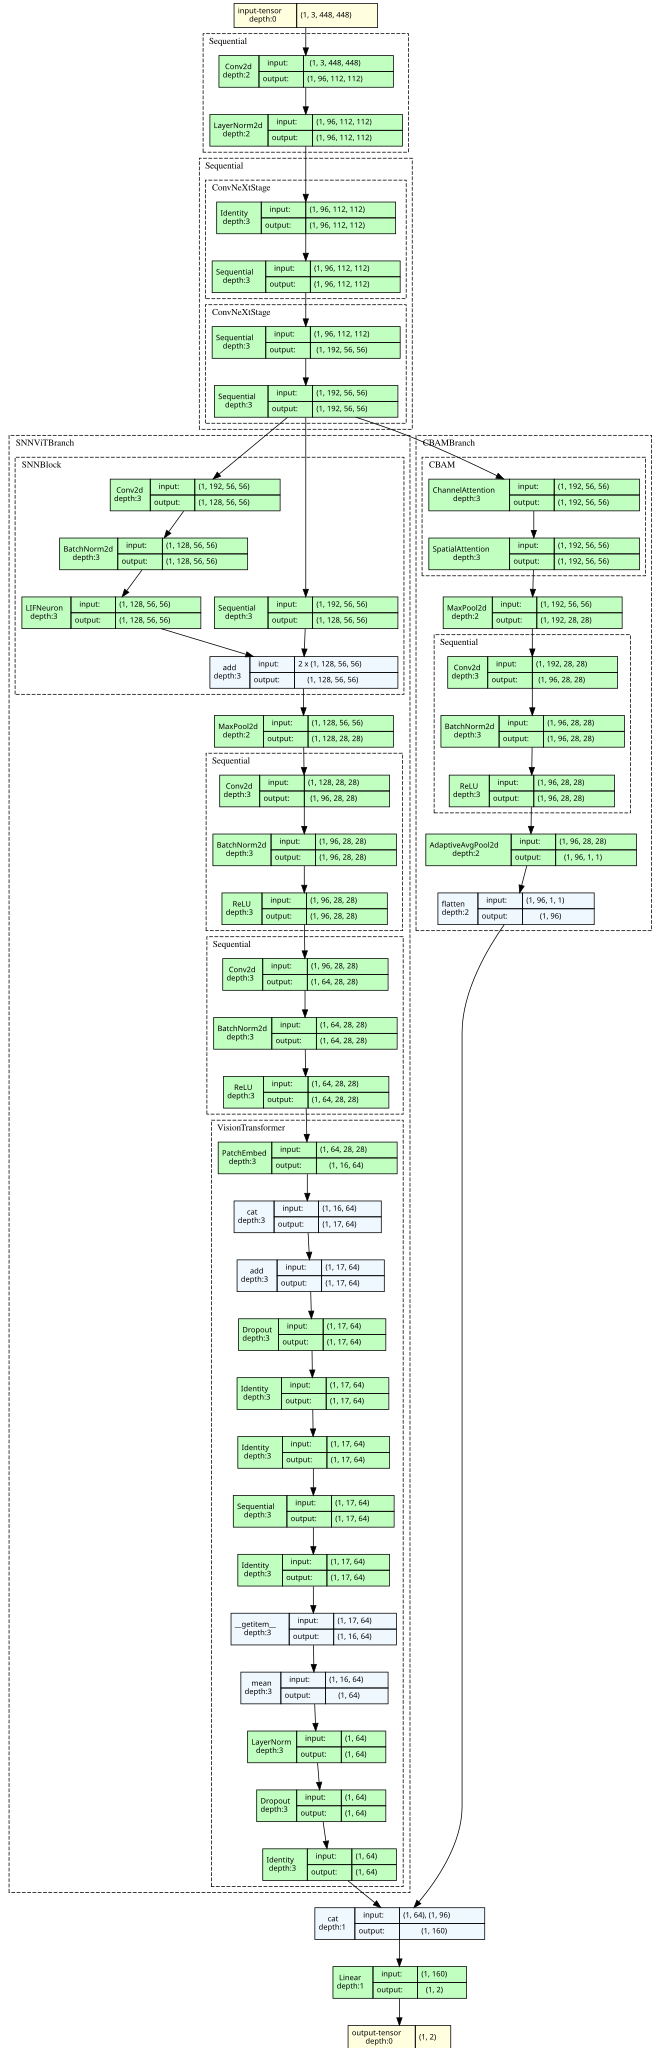

In [13]:
from torchview import draw_graph
from IPython.display import SVG, display

dummy_input = torch.randn(1, 3, 448, 448).to(device)

graph = draw_graph(
    model,
    input_data=dummy_input,
    expand_nested=True,
    graph_name="ConvNeXtCBAMViT",
    save_graph=True,              # IMPORTANT
    filename="ConvNeXtCBAMViT_BlockDiagram",
    directory="."
)

# Display inline
svg = graph.visual_graph.pipe(format="svg")
display(SVG(svg))


## 12. Training and validation

In [14]:

history = {
    "loss": [], "val_loss": [],
    "accuracy": [], "val_accuracy": [],
    "precision": [], "val_precision": [],
    "recall": [], "val_recall": [],
    "f1": [], "val_f1": [],
    "auc": [], "val_auc": [],
    "mcc": [], "val_mcc": [],
    "specificity": [], "val_specificity": [],
    "sensitivity": [], "val_sensitivity": []
}

# Track the best validation accuracy for checkpoint saving.
# No early stopping will be performed.
best_val_acc = -1.0
best_epoch = 0

for epoch in range(TOTAL_EPOCHS):

    # -------------------- TRAIN --------------------
    model.train()
    running_loss = 0.0
    train_true, train_pred, train_prob = [], [], []

    pbar = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{TOTAL_EPOCHS} - Train"
    )

    for images, labels in pbar:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            enabled=USE_AMP
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()

        probs = torch.softmax(outputs.detach(), dim=1)

        train_true.extend(labels.detach().cpu().numpy())
        train_pred.extend(
            outputs.detach().argmax(1).cpu().numpy()
        )
        train_prob.extend(probs.cpu().numpy())

        pbar.set_postfix(
            loss=f"{loss.item():.4f}",
            lr=f"{optimizer.param_groups[0]['lr']:.2e}"
        )

    train_loss = running_loss / max(1, len(train_loader))

    train_metrics = calculate_metrics(
        np.asarray(train_true),
        np.asarray(train_pred),
        np.asarray(train_prob),
        num_classes
    )

    # -------------------- VALIDATION --------------------
    model.eval()

    val_running_loss = 0.0
    val_true, val_pred, val_prob = [], [], []

    with torch.no_grad():

        for images, labels in tqdm(
            val_loader,
            desc=f"Epoch {epoch+1}/{TOTAL_EPOCHS} - Val"
        ):

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(
                device_type=device.type,
                enabled=USE_AMP
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            val_running_loss += loss.item()

            probs = torch.softmax(outputs, dim=1)

            val_true.extend(labels.cpu().numpy())
            val_pred.extend(outputs.argmax(1).cpu().numpy())
            val_prob.extend(probs.cpu().numpy())

    val_loss = val_running_loss / max(1, len(val_loader))

    val_metrics = calculate_metrics(
        np.asarray(val_true),
        np.asarray(val_pred),
        np.asarray(val_prob),
        num_classes
    )

    # -------------------- LEARNING RATE SCHEDULER --------------------
    if epoch < WARMUP_EPOCHS:
        warmup_scheduler.step()
    else:
        cosine_scheduler.step()

    # -------------------- SAVE HISTORY --------------------
    history["loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    for key in train_metrics:
        history[key].append(train_metrics[key])
        history[f"val_{key}"].append(val_metrics[key])

    # -------------------- PRINT METRICS --------------------
    print(
        f"\nEpoch {epoch+1}/{TOTAL_EPOCHS}: "
        f"train loss={train_loss:.4f}, "
        f"acc={train_metrics['accuracy']:.4f}, "
        f"F1={train_metrics['f1']:.4f}, "
        f"AUC={train_metrics['auc']:.4f} | "
        f"val loss={val_loss:.4f}, "
        f"acc={val_metrics['accuracy']:.4f}, "
        f"F1={val_metrics['f1']:.4f}, "
        f"AUC={val_metrics['auc']:.4f}"
    )

    print(
        f"Val precision={val_metrics['precision']:.4f}, "
        f"recall={val_metrics['recall']:.4f}, "
        f"specificity={val_metrics['specificity']:.4f}, "
        f"sensitivity={val_metrics['sensitivity']:.4f}, "
        f"MCC={val_metrics['mcc']:.4f}"
    )

    print(
        f"Learning rate: "
        f"{optimizer.param_groups[0]['lr']:.6e}"
    )

    # -------------------- SAVE BEST MODEL --------------------
    if val_metrics["accuracy"] > best_val_acc:

        best_val_acc = val_metrics["accuracy"]
        best_epoch = epoch + 1

        torch.save({
            "model_state_dict": model.state_dict(),
            "num_classes": num_classes,
            "class_to_idx": label_map,
            "best_val_accuracy": best_val_acc,
            "epoch": epoch + 1,
            "architecture": "ConvNeXt-Tiny + SNN + CBAM + Vision Transformer + Feature Fusion"
        }, BEST_MODEL_PATH)

        print(
            f"Saved best checkpoint "
            f"(Epoch {best_epoch}, "
            f"Val Accuracy={best_val_acc:.4f})"
        )

    else:
        print(
            f"Best checkpoint retained from Epoch {best_epoch}."
        )

    # NO EARLY STOPPING: training always continues.


# -------------------- FINAL TRAINING SUMMARY --------------------
print("\n" + "=" * 60)
print("TRAINING COMPLETED")
print("=" * 60)

print(f"Total epochs completed: {len(history['loss'])}")
print(f"Best validation accuracy: {best_val_acc:.4f}")
print(f"Best epoch: {best_epoch}")
print(f"Best model saved at: {BEST_MODEL_PATH}")


Epoch 1/20 - Train:   0%|          | 0/1120 [00:00<?, ?it/s]

Epoch 1/20 - Val:   0%|          | 0/280 [00:00<?, ?it/s]


Epoch 1/20: train loss=0.4015, acc=0.8761, F1=0.8224, AUC=0.9218 | val loss=0.3791, acc=0.9017, F1=0.8498, AUC=0.9721
Val precision=0.9095, recall=0.8156, specificity=0.8156, sensitivity=0.8156, MCC=0.7190
Learning rate: 8.400000e-05
Saved best checkpoint (Epoch 1, Val Accuracy=0.9017)


Epoch 2/20 - Train:   0%|          | 0/1120 [00:00<?, ?it/s]

Epoch 2/20 - Val:   0%|          | 0/280 [00:00<?, ?it/s]


Epoch 2/20: train loss=0.3775, acc=0.8983, F1=0.8562, AUC=0.9386 | val loss=0.3270, acc=0.9223, F1=0.9019, AUC=0.9850
Val precision=0.8794, recall=0.9368, specificity=0.9368, sensitivity=0.9368, MCC=0.8142
Learning rate: 1.380000e-04
Saved best checkpoint (Epoch 2, Val Accuracy=0.9223)


... (62 outputs left out)


Epoch 19/20: train loss=0.2029, acc=0.9983, F1=0.9977, AUC=0.9999 | val loss=0.2208, acc=0.9897, F1=0.9861, AUC=0.9965
Val precision=0.9812, recall=0.9913, specificity=0.9913, sensitivity=0.9913, MCC=0.9725
Learning rate: 4.266934e-06
Best checkpoint retained from Epoch 15.


Epoch 20/20 - Train:   0%|          | 0/1120 [00:00<?, ?it/s]

Epoch 20/20 - Val:   0%|          | 0/280 [00:00<?, ?it/s]


Epoch 20/20: train loss=0.2011, acc=0.9987, F1=0.9982, AUC=1.0000 | val loss=0.2181, acc=0.9911, F1=0.9879, AUC=0.9962
Val precision=0.9843, recall=0.9916, specificity=0.9916, sensitivity=0.9916, MCC=0.9759
Learning rate: 1.000000e-06
Saved best checkpoint (Epoch 20, Val Accuracy=0.9911)

TRAINING COMPLETED
Total epochs completed: 20
Best validation accuracy: 0.9911
Best epoch: 20
Best model saved at: best_convnext_cbam_vit.pth


## 13. Plot training curves

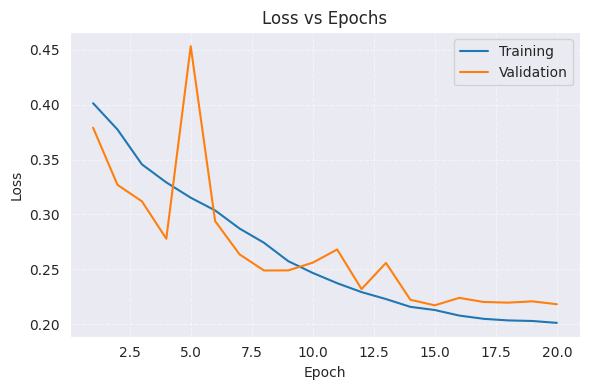

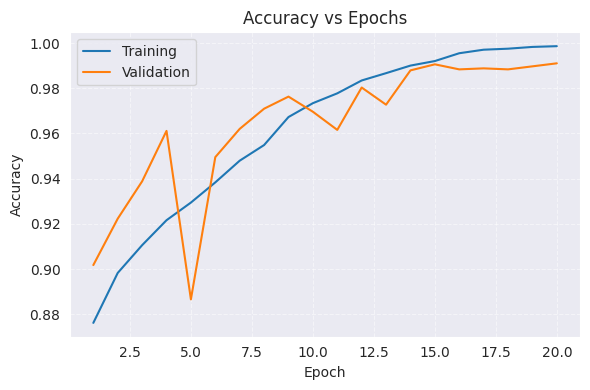

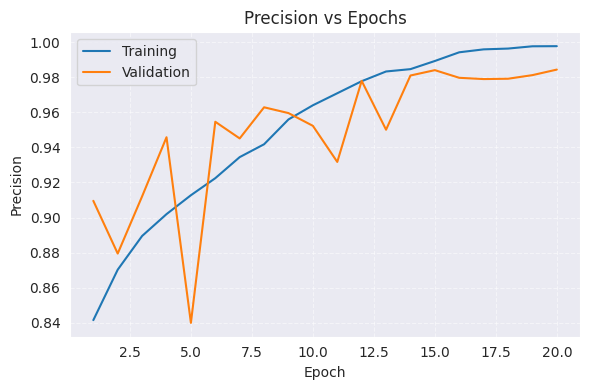

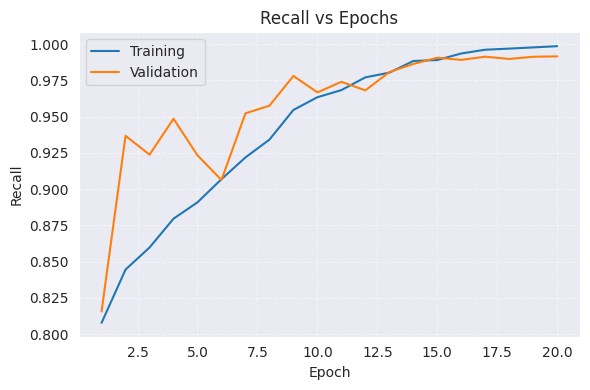

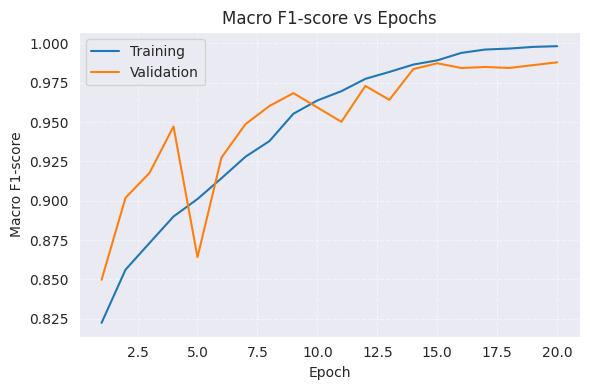

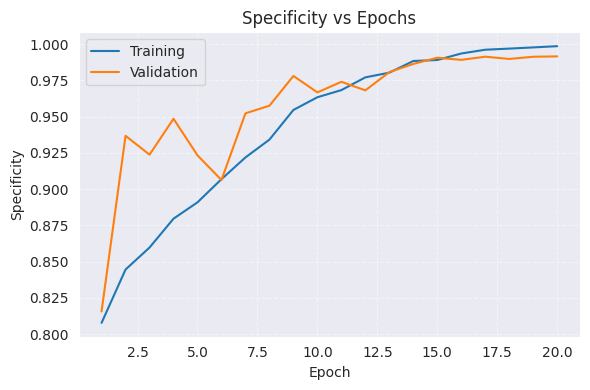

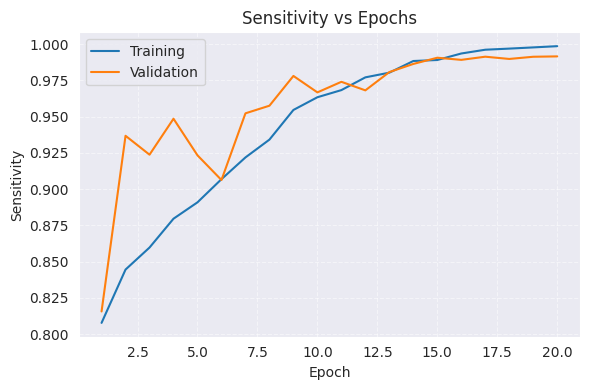

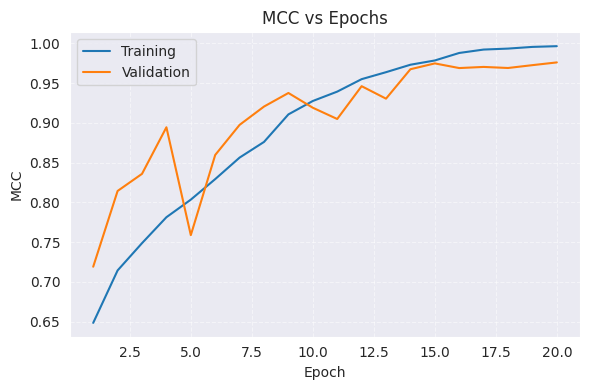

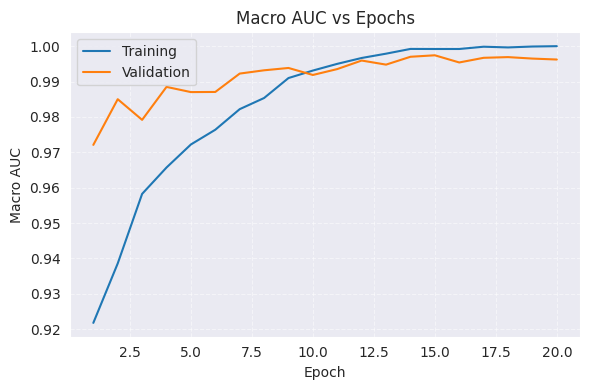

In [15]:
def plot_metric(train_values, val_values, title, ylabel):
    epochs = range(1, len(train_values) + 1)
    plt.figure(figsize=(6, 4))
    plt.plot(epochs, train_values, label="Training")
    plt.plot(epochs, val_values, label="Validation")
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

plot_metric(history["loss"], history["val_loss"], "Loss vs Epochs", "Loss")
for metric, title in [
    ("accuracy", "Accuracy"), ("precision", "Precision"), ("recall", "Recall"),
    ("f1", "Macro F1-score"), ("specificity", "Specificity"),
    ("sensitivity", "Sensitivity"), ("mcc", "MCC"), ("auc", "Macro AUC")
]:
    plot_metric(history[metric], history[f"val_{metric}"], f"{title} vs Epochs", title)

## 14. Load best checkpoint and evaluate on the test set

In [16]:
checkpoint = torch.load(BEST_MODEL_PATH, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

all_targets, all_preds, all_probs = [], [], []
test_loss = 0.0
with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Testing"):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            outputs = model(images)
            loss = criterion(outputs, labels)
        test_loss += loss.item()
        all_targets.extend(labels.cpu().numpy())
        all_preds.extend(outputs.argmax(1).cpu().numpy())
        all_probs.extend(torch.softmax(outputs, dim=1).cpu().numpy())

all_targets = np.asarray(all_targets)
all_preds = np.asarray(all_preds)
all_probs = np.asarray(all_probs)
test_metrics = calculate_metrics(all_targets, all_preds, all_probs, num_classes)

print(f"Test loss: {test_loss / max(1, len(test_loader)):.4f}")
for key, value in test_metrics.items():
    print(f"{key}: {value:.4f}")

Testing:   0%|          | 0/32 [00:00<?, ?it/s]

Test loss: 0.4210
accuracy: 0.9012
precision: 0.8970
recall: 0.9175
f1: 0.8994
mcc: 0.8143
auc: 0.9508
specificity: 0.9175
sensitivity: 0.9175


## 15. Classification report and confusion matrix

              precision    recall  f1-score   support

    No Tumor     0.8017    0.9898    0.8858        98
       Tumor     0.9924    0.8452    0.9129       155

    accuracy                         0.9012       253
   macro avg     0.8970    0.9175    0.8994       253
weighted avg     0.9185    0.9012    0.9024       253



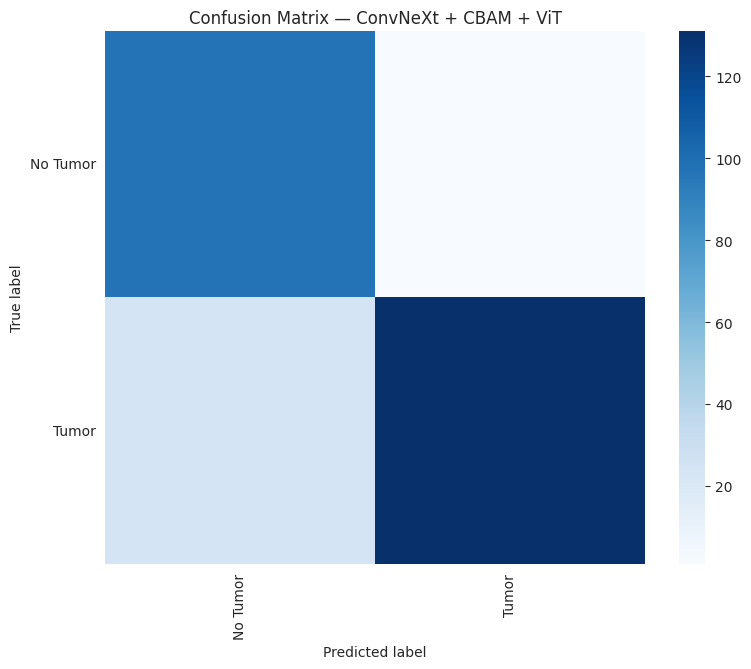

In [17]:
class_names = [idx_to_class[i] for i in range(num_classes)]
print(classification_report(
    all_targets, all_preds, labels=list(range(num_classes)),
    target_names=class_names, digits=4, zero_division=0
))

cm = confusion_matrix(all_targets, all_preds, labels=list(range(num_classes)))
fig_size = max(8, min(18, 0.45 * num_classes + 5))
plt.figure(figsize=(fig_size, fig_size * 0.85))
sns.heatmap(cm, cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion Matrix — ConvNeXt + CBAM + ViT")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 16. Grad-CAM visualizations

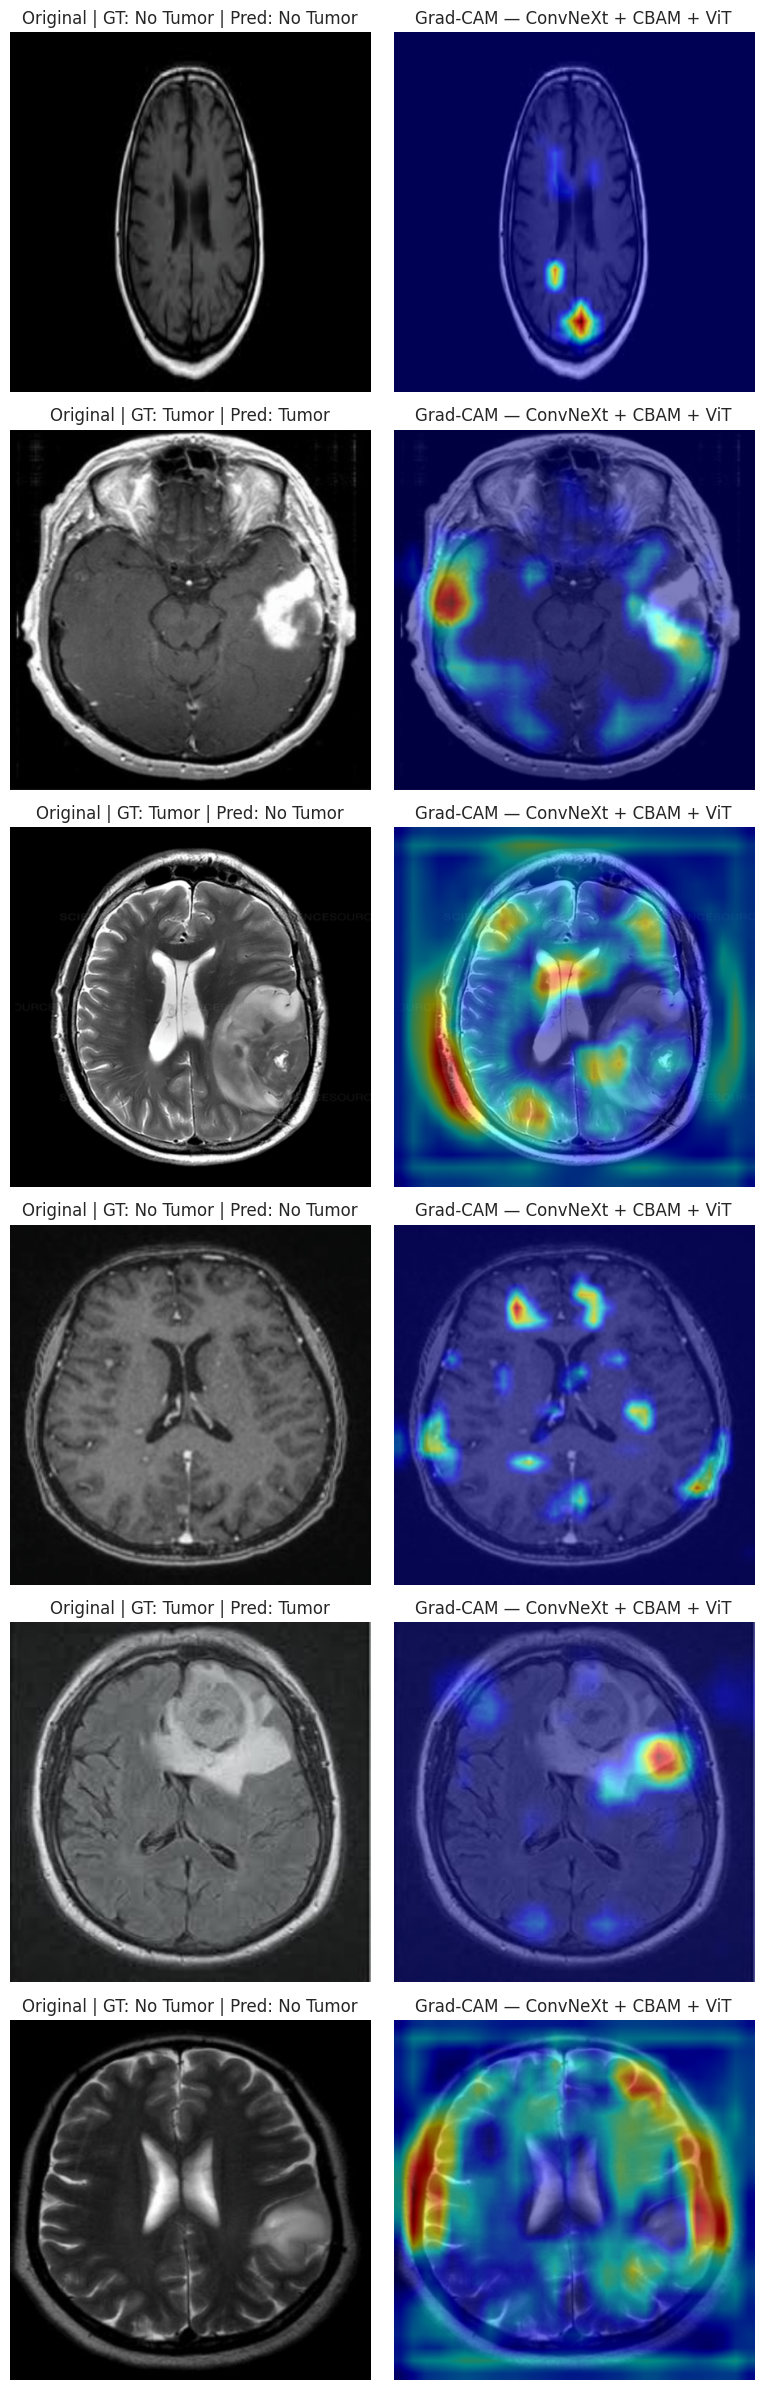

In [18]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# Grad-CAM target: the 3x3 convolution immediately before ViT patch embedding.
target_layers = [model.main_branch.conv3x3[0]]
cam = GradCAM(model=model, target_layers=target_layers)

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
num_images = min(6, len(test_loader.dataset))
indices = np.random.choice(len(test_loader.dataset), num_images, replace=False)

fig, axes = plt.subplots(num_images, 2, figsize=(8, 4 * num_images))
if num_images == 1:
    axes = np.expand_dims(axes, axis=0)

model.eval()
for i, idx in enumerate(indices):
    img, label = test_loader.dataset[idx]
    input_tensor = img.unsqueeze(0).to(device)

    with torch.no_grad():
        pred_class = model(input_tensor).argmax(dim=1).item()

    rgb = img.permute(1, 2, 0).cpu().numpy()
    rgb = np.clip(rgb * std + mean, 0, 1)
    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=[ClassifierOutputTarget(pred_class)]
    )[0]
    visualization = show_cam_on_image(rgb, grayscale_cam, use_rgb=True)

    axes[i, 0].imshow(rgb)
    axes[i, 0].set_title(f"Original | GT: {idx_to_class[int(label)]} | Pred: {idx_to_class[pred_class]}")
    axes[i, 0].axis("off")
    axes[i, 1].imshow(visualization)
    axes[i, 1].set_title("Grad-CAM — ConvNeXt + CBAM + ViT")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()


## 17. Save final experiment metadata

The experiment metadata records the binary `No Tumor` / `Tumor` task, the FFT dataset recipe, the stratified 80/20 train-validation split, and the independent yes/no external test set.


In [19]:
experiment_summary = {
    "experiment": "ConvNeXt-Tiny + SNN + CBAM + ViT — Binary Tumor/No Tumor",
    "dataset_recipe": (
        "FFT_Model_best: Mendeley Train+Test pooled; sample up to 3300 glioma, "
        "2800 meningioma, 2000 pituitary, all no_tumor; add 171 Astrocitoma T2, "
        "233 Meningioma T2, 57 Ependimoma T2 as Tumor and 271 Normal T2 as No Tumor."
    ),
    "training_validation_split": "stratified 80% train / 20% validation (random_state=42)",
    "external_test": "brain_mri_detection yes/no dataset, kept separate and unchanged",
    "class_to_idx": label_map,
    "num_classes": num_classes,
    "input_shape": [3, 448, 448],
    "architecture": "ConvNeXt-Tiny + SNN + CBAM parallel branch + ViT + fused binary classifier",
    "best_validation_accuracy": float(best_val_acc),
    "test_metrics": {k: float(v) for k, v in test_metrics.items()},
    "total_parameters": int(total_params),
    "trainable_parameters": int(trainable_params),
    "thop_flops": int(flops)
}

with open("convnext_snn_vit_cbam_binary_results.json", "w") as f:
    json.dump(experiment_summary, f, indent=2)

print(json.dumps(experiment_summary, indent=2))


{
  "experiment": "ConvNeXt-Tiny + SNN + CBAM + ViT \u2014 Binary Tumor/No Tumor",
  "dataset_recipe": "FFT_Model_best: Mendeley Train+Test pooled; sample up to 3300 glioma, 2800 meningioma, 2000 pituitary, all no_tumor; add 171 Astrocitoma T2, 233 Meningioma T2, 57 Ependimoma T2 as Tumor and 271 Normal T2 as No Tumor.",
  "training_validation_split": "stratified 80% train / 20% validation (random_state=42)",
  "external_test": "brain_mri_detection yes/no dataset, kept separate and unchanged",
  "class_to_idx": {
    "No Tumor": 0,
    "Tumor": 1
  },
  "num_classes": 2,
  "input_shape": [
    3,
    448,
    448
  ],
  "architecture": "ConvNeXt-Tiny + SNN + CBAM parallel branch + ViT + fused binary classifier",
  "best_validation_accuracy": 0.9910674408217954,
  "test_metrics": {
    "accuracy": 0.9011857707509882,
    "precision": 0.897038567493113,
    "recall": 0.9174786043449639,
    "f1": 0.8993683674605826,
    "mcc": 0.8142606634933276,
    "auc": 0.9507899934167214,
    "speci

In [19]:
0
